# 文体の特徴から文章の書き手を推定する (計量文体学)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/07_corpus_statistics/authorship_attribution.ipynb)

NLP クックブック 07-12 ／ コーパスの統計と可視化

作者を伏せた文章の断片を、読点の打ち方や助詞の使い方などの文体の特徴から、どの作家が書いたか当てたい。話題 (内容語) ではなく文体で当てていることも確かめたい。

In [1]:
!pip install -q datasets fugashi unidic-lite matplotlib-fontja

In [2]:
import random, re
from collections import Counter
import numpy as np
import pandas as pd
from datasets import load_dataset
from fugashi import Tagger

# 青空文庫を整形したデータセット (GLOBIS 大学、CC BY 4.0。収録作品はパブリックドメイン)。約 240MB、初回はダウンロードに 1〜2 分
ds = load_dataset("globis-university/aozorabunko-clean", split="train")

AUTHORS = ["夏目漱石", "森鴎外", "芥川竜之介", "太宰治", "宮沢賢治", "坂口安吾"]
MAX_WORKS, MAX_FRAGS, FRAG_CHARS = 24, 4, 2000
random.seed(0)

def series(title):
    """版違い (「（初稿）」) や続き物 (「彼　第二」) を同じ作品として扱うための名前"""
    return re.sub(r"[（(].*?[）)]|[\s　]*第[一二三四五六七八九十]+$", "", title).strip()

works = {a: {} for a in AUTHORS}
for ex in ds:
    m = ex["meta"]
    name = m["姓"] + m["名"]
    # 表記をそろえるため新字新仮名、ジャンルをそろえるため小説・物語 (NDC 913。児童書の K913 も含む) に限る。
    # 随筆や序文を兼ねるもの (「NDC 913 914」など) と短すぎる作品は除く
    if (name in works and m["役割フラグ"] == "著者" and m["文字遣い種別"] == "新字新仮名"
            and m["分類番号"] in ("NDC 913", "NDC K913") and len(ex["text"]) >= 2 * FRAG_CHARS):
        # 連作 (「明治開化　安吾捕物」の各回など) は作品名が同じで作品 ID が別。登場人物が共通なので 1 本だけ残す
        works[name].setdefault(series(m["作品名"]), ex["text"])

def fragments(text):
    """段落の切れ目で約 FRAG_CHARS 字ずつに区切り、作品全体から等間隔に MAX_FRAGS 個を選ぶ"""
    chunks, buf = [], ""
    for para in text.split("\n"):
        buf += para.strip() + "\n"
        if len(buf) >= FRAG_CHARS:
            chunks.append(buf); buf = ""
    idx = np.linspace(0, len(chunks) - 1, min(MAX_FRAGS, len(chunks))).round().astype(int)
    return [chunks[i] for i in sorted(set(idx))]

rows = []
for author, ws in works.items():
    for title, text in random.sample(list(ws.items()), min(MAX_WORKS, len(ws))):
        # 作品名は作家をまたいで重なる (「手紙」「母」など) ので、作家名と組にしてグループの ID にする
        rows += [{"author": author, "work_id": f"{author}/{title}", "text": f} for f in fragments(text)]
df = pd.DataFrame(rows)
print(df.groupby("author").agg(作品数=("work_id", "nunique"), 断片数=("text", "size")))

        作品数  断片数
author          
坂口安吾     24   88
夏目漱石     24   94
太宰治      24   82
宮沢賢治     24   65
森鴎外      24   87
芥川竜之介    24   70


In [3]:
# 形態素解析して、文体の特徴量を作るための列を用意する (Colab の CPU で 10〜20 秒)
tagger = Tagger()
FUNC = {"助詞", "助動詞"}          # 機能語として扱う品詞
KEEP = FUNC | {"補助記号"}          # 内容語を伏せるときに残す品詞

def analyze(text):
    toks = [(w.surface, w.feature.pos1, w.feature.pos2) for line in text.split("\n") for w in tagger(line)]
    sents = [s for s in re.split(r"(?<=[。！？])|\n", text) if s.strip()]
    n_chars = len(re.sub(r"\s", "", text))
    talk = sum(len(t) for t in re.findall(r"「[^」]*」", text))
    return {
        # 1. 文体の基本統計 (文の長さ、読点の多さ、字種の割合、会話文の割合)
        "文の長さ (平均)": np.mean([len(s) for s in sents]),
        "文の長さ (標準偏差)": np.std([len(s) for s in sents]),
        "1 文あたりの読点": text.count("、") / len(sents),
        "漢字の割合": len(re.findall(r"[一-龥々]", text)) / n_chars,
        "ひらがなの割合": len(re.findall(r"[ぁ-ん]", text)) / n_chars,
        "カタカナの割合": len(re.findall(r"[ァ-ヶー]", text)) / n_chars,
        "会話文の割合": talk / n_chars,
        # 2. 読点の直前の品詞 (どこで読点を打つか)
        "comma_pos": " ".join(f"{p1}-{p2}" for (s, p1, p2), nxt in zip(toks, toks[1:]) if nxt[0] == "、"),
        "comma_char": " ".join(text[i - 1] for i in range(1, len(text)) if text[i] == "、"),   # 読点の直前の文字
        # 3. 助詞・助動詞の並び
        "func": " ".join(s for s, p1, _ in toks if p1 in FUNC),
        # 4. 品詞の並び
        "pos": " ".join(p1 for _, p1, _ in toks),
        # 5. 内容語を品詞名に置き換えた文 (助詞・助動詞・記号だけが残る)
        "masked": " ".join(s if p1 in KEEP else f"[{p1}]" for s, p1, _ in toks),
        "masked_np": " ".join(s if p1 in FUNC else f"[{p1}]" for s, p1, _ in toks if p1 != "補助記号"),  # 記号も除く
        # 6. 内容語だけ (話題の手がかり。比較用)
        "content": " ".join(s for s, p1, p2 in toks if p1 in ("名詞", "動詞", "形容詞") and p2 != "非自立可能"),
    }

feats = pd.DataFrame([analyze(t) for t in df["text"]])
STATS = [c for c in feats.columns if feats[c].dtype != object]
print(feats[STATS].groupby(df["author"]).mean().round(3).to_string())

        文の長さ (平均)  文の長さ (標準偏差)  1 文あたりの読点  漢字の割合  ひらがなの割合  カタカナの割合  会話文の割合
author                                                                    
坂口安吾       31.856       22.307      1.157  0.263    0.600    0.057   0.290
夏目漱石       30.096       18.517      0.763  0.304    0.610    0.010   0.241
太宰治        32.187       33.275      1.906  0.242    0.635    0.019   0.206
宮沢賢治       27.816       22.421      0.822  0.196    0.695    0.030   0.307
森鴎外        32.914       21.580      1.160  0.324    0.585    0.007   0.195
芥川竜之介      29.157       18.465      1.165  0.297    0.588    0.019   0.288


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def words(ngram=(1, 1)):   # 空白区切りのトークン列を n-gram の TF-IDF にする
    return TfidfVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=ngram, min_df=2, sublinear_tf=True)

SETS = {   # 名前: (使う列, 特徴量の作り方)
    "文体の基本統計":            (STATS, StandardScaler()),
    "読点の直前の文字":          ("comma_char", words()),
    "読点の直前の品詞":          ("comma_pos", words()),
    "助詞・助動詞 (1〜2-gram)":  ("func", words((1, 2))),
    "品詞 (1〜3-gram)":          ("pos", words((1, 3))),
    "内容語を伏せた文 (1〜3-gram)": ("masked", words((1, 3))),
    "　同 (記号も除く)":          ("masked_np", words((1, 3))),
    "内容語 (比較用)":           ("content", words()),
    "文字 (1〜3-gram、全部入り)": ("text", TfidfVectorizer(analyzer="char", ngram_range=(1, 3), min_df=2, sublinear_tf=True)),
}
data = pd.concat([df[["author", "work_id", "text"]], feats], axis=1)
y, groups = data["author"].values, data["work_id"].values
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(data, y, groups))  # 作品単位で 5 分割

def work_bootstrap(correct, n_boot=1000, seed=0):
    """作品を単位に復元抽出して、正解率の 95% 信頼区間を求める"""
    rng = np.random.default_rng(seed)
    by_work = pd.Series(correct).groupby(groups)
    s, n = by_work.sum().values, by_work.size().values
    idx = rng.integers(0, len(s), (n_boot, len(s)))
    return np.percentile(s[idx].sum(1) / n[idx].sum(1), [2.5, 97.5])

preds, results = {}, []   # 9 種類 × 5 分割の学習。Colab の CPU で 2〜3 分
for name, (col, vec) in SETS.items():
    pred = np.empty(len(y), dtype=object)
    for tr, te in cv:
        clf = make_pipeline(vec, LogisticRegression(C=10, max_iter=5000))
        clf.fit(data.iloc[tr][col], y[tr])
        pred[te] = clf.predict(data.iloc[te][col])
    preds[name] = pred
    lo, hi = work_bootstrap(pred == y)
    results.append((name, accuracy_score(y, pred), lo, hi, f1_score(y, pred, average="macro")))
pd.DataFrame(results, columns=["特徴量", "正解率", "95%CI 下", "95%CI 上", "マクロ F1"]).round(3)

,特徴量,正解率,95%CI 下,95%CI 上,マクロ F1
0,文体の基本統計,0.607,0.545,0.667,0.605
1,読点の直前の文字,0.788,0.741,0.832,0.786
2,読点の直前の品詞,0.650,0.598,0.698,0.647
3,助詞・助動詞 (1〜2-gram),0.860,0.814,0.899,0.862
4,品詞 (1〜3-gram),0.881,0.844,0.914,0.888
5,内容語を伏せた文 (1〜3-gram),0.944,0.916,0.969,0.945
6,同 (記号も除く),0.922,0.885,0.954,0.923
7,内容語 (比較用),0.975,0.953,0.992,0.975
8,文字 (1〜3-gram、全部入り),0.977,0.958,0.992,0.978


In [5]:
def paired_diff(a, b, n_boot=1000, seed=0):
    """同じ作品の組を復元抽出して、2 つの特徴量の正解率の差の 95% 信頼区間を求める"""
    rng = np.random.default_rng(seed)
    by = pd.DataFrame({"a": preds[a] == y, "b": preds[b] == y}).groupby(groups)
    sa, sb, n = by["a"].sum().values, by["b"].sum().values, by.size().values
    idx = rng.integers(0, len(n), (n_boot, len(n)))
    d = (sa[idx].sum(1) - sb[idx].sum(1)) / n[idx].sum(1)
    return (sa.sum() - sb.sum()) / n.sum(), *np.percentile(d, [2.5, 97.5])

M = "内容語を伏せた文 (1〜3-gram)"
for a, b in [("内容語 (比較用)", M), ("文字 (1〜3-gram、全部入り)", M), (M, "　同 (記号も除く)")]:
    d, lo, hi = paired_diff(a, b)
    print(f"{a} − {b.strip()}: {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")

内容語 (比較用) − 内容語を伏せた文 (1〜3-gram): +0.031 [+0.004, +0.061]
文字 (1〜3-gram、全部入り) − 内容語を伏せた文 (1〜3-gram): +0.033 [+0.010, +0.060]
内容語を伏せた文 (1〜3-gram) − 同 (記号も除く): +0.023 [+0.000, +0.049]


In [6]:
# Burrows の Delta: 頻出語の相対頻度を z 得点にし、各作家の平均との差の絶対値の平均が最も小さい作家を答える
from sklearn.feature_extraction.text import CountVectorizer

n_tok = data["masked"].str.split().str.len().values[:, None]   # 断片の全トークン数 (相対頻度の分母)

def delta_predict(col, n_mfw):
    pred = np.empty(len(y), dtype=object)
    for tr, te in cv:
        cnt = CountVectorizer(token_pattern=r"\S+", lowercase=False, max_features=n_mfw).fit(data.iloc[tr][col])  # 学習側の頻出語
        X = cnt.transform(data[col]).toarray().astype(float)
        X /= n_tok                                                         # 全トークン数に対する相対頻度
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        Z = (X - mu) / sd
        centroids = np.stack([Z[tr][y[tr] == a].mean(0) for a in AUTHORS])
        dist = np.abs(Z[te][:, None, :] - centroids[None]).mean(2)         # Delta
        pred[te] = np.array(AUTHORS)[dist.argmin(1)]
    return pred

for col, label in [("func", "助詞・助動詞"), ("masked", "内容語を伏せた文の語")]:
    for n_mfw in (50, 150):
        pred = delta_predict(col, n_mfw)
        lo, hi = work_bootstrap(pred == y)
        print(f"Delta ({label}、上位 {n_mfw} 語): 正解率 {accuracy_score(y, pred):.3f} [{lo:.3f}, {hi:.3f}]")

Delta (助詞・助動詞、上位 50 語): 正解率 0.691 [0.637, 0.748]
Delta (助詞・助動詞、上位 150 語): 正解率 0.648 [0.589, 0.709]
Delta (内容語を伏せた文の語、上位 50 語): 正解率 0.693 [0.639, 0.747]
Delta (内容語を伏せた文の語、上位 150 語): 正解率 0.763 [0.711, 0.814]


In [7]:
# 間違え方を見る (内容語を伏せた文の分類器)
print(pd.crosstab(pd.Series(y, name="正解"), pd.Series(preds["内容語を伏せた文 (1〜3-gram)"], name="予測")))

# 作家ごとに特に多い・少ない助詞・助動詞 (相対頻度の z 得点の平均)
cnt = CountVectorizer(token_pattern=r"\S+", lowercase=False, max_features=40).fit(data["func"])
X = cnt.transform(data["func"]).toarray() / n_tok
Z = pd.DataFrame((X - X.mean(0)) / X.std(0), columns=cnt.get_feature_names_out()).groupby(y).mean()
for a in AUTHORS:
    z = Z.loc[a].sort_values()
    print(f"{a}: 多い {list(z.index[::-1][:5])}  少ない {list(z.index[:3])}")

# 比較用: 内容語の分類器は何を手がかりにしているか (手がかりを見るために全データで学習し、係数の大きい語を出す)
clf = make_pipeline(words(), LogisticRegression(C=10, max_iter=5000)).fit(data["content"], y)
vocab = clf[0].get_feature_names_out()
for a, coef in zip(clf[1].classes_, clf[1].coef_):
    print(f"{a}: {list(vocab[coef.argsort()[::-1][:10]])}")

予測     坂口安吾  夏目漱石  太宰治  宮沢賢治  森鴎外  芥川竜之介
正解                                      
坂口安吾     78     2    5     3    0      0
夏目漱石      1    93    0     0    0      0
太宰治       3     1   76     0    2      0
宮沢賢治      0     3    0    62    0      0
森鴎外       1     2    0     0   84      0
芥川竜之介     0     0    2     0    2     66
夏目漱石: 多い ['と', 'から', 'まで', 'へ', 'ん']  少ない ['せ', 'まし', 'でし']
森鴎外: 多い ['に', 'て', 'られ', 'を', 'せ']  少ない ['も', 'ながら', 'ん']
芥川竜之介: 多い ['ながら', 'ばかり', 'は', 'です', 'か']  少ない ['て', 'が', 'で']
太宰治: 多い ['な', 'も', 'で', 'たら', 'て']  少ない ['を', 'へ', 'が']
宮沢賢治: 多い ['まし', 'でし', 'や', 'ん', 'ます']  少ない ['に', 'ず', 'と']
坂口安吾: 多い ['が', 'だ', 'で', 'だけ', 'ない']  少ない ['ながら', 'ばかり', 'まし']
坂口安吾: ['こと', 'バカ', 'で', 'きい', 'よっ', '冷め', '戻っ', '痴川', '気持', '怖れ']
夏目漱石: ['事', '自分', '所', '三四郎', '重吉', '出る', '兄', '訳', '分ら', '津田']
太宰治: ['ひと', 'いま', 'ひとり', '言っ', 'ほう', '言い', '於い', 'まえ', 'へん', '気持']
宮沢賢治: ['みんな', '云い', '叫び', '野原', '木', '向う', 'みな', '青い', 'とこ', 'ブドリ']
森鴎外: ['処', '詞', '物', '目', '遣っ', '跡', '為事', '初め', 

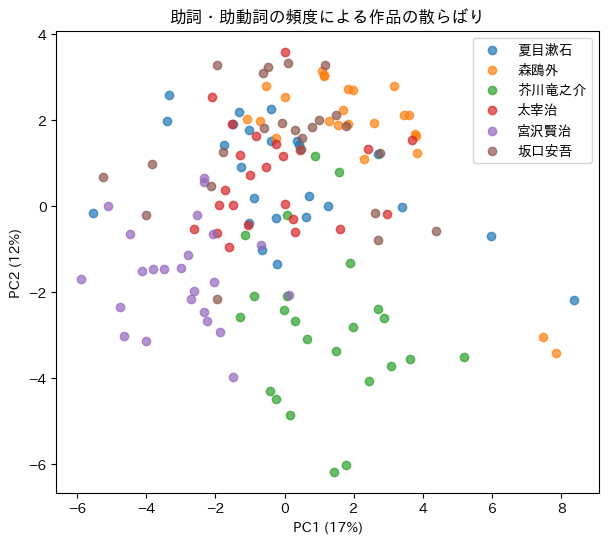

PC1: + 側 ['に', 'を', 'ず', 'ぬ', 'より', 'の']  - 側 ['だ', 'から', 'な', 'ん', 'よ', 'まし']
PC2: + 側 ['で', 'が', 'て', 'と', 'から', 'だ']  - 側 ['ませ', 'です', 'ん', 'ばかり', 'まし', 'ながら']


In [8]:
import matplotlib.pyplot as plt
import matplotlib_fontja
from sklearn.decomposition import PCA

# 作品ごとに助詞・助動詞の相対頻度をまとめ、主成分分析で 2 次元にする
W = pd.DataFrame(X, columns=cnt.get_feature_names_out()).groupby(data["work_id"].values).mean()
work_author = data.groupby("work_id")["author"].first().loc[W.index]
pca = PCA(n_components=2, random_state=0)
P = pca.fit_transform(StandardScaler().fit_transform(W))

fig, ax = plt.subplots(figsize=(7, 6))
for a in AUTHORS:
    m = (work_author == a).values
    ax.scatter(P[m, 0], P[m, 1], label=a, alpha=0.7)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("助詞・助動詞の頻度による作品の散らばり"); ax.legend(); plt.show()

for i in range(2):
    load = pd.Series(pca.components_[i], index=W.columns).sort_values()
    print(f"PC{i + 1}: + 側 {list(load.index[::-1][:6])}  - 側 {list(load.index[:6])}")

- 学習と評価は作品単位で分ける (`groups` に作家名と作品名)。同じ作品の断片が両側に入ると、登場人物の名前や話題で当たり、評価が甘くなる。青空文庫では連作 (「明治開化　安吾捕物」の各回など) が別々の作品 ID で入っているので、作品名で 1 本にまとめた。題名の違う連作 (芥川の「保吉」もの) はこれでは除けない。データの収集と入出力の章の「データを学習・開発・評価に正しく分割する」も参照。
- 6 人 × 24 作品の 486 断片 (約 2000 字ずつ) で、内容語を品詞名に伏せた文の 1〜3-gram が正解率 0.944 (作品単位のブートストラップで 95% 信頼区間 0.916〜0.969)。品詞の並びだけで 0.881、助詞・助動詞だけで 0.860 だった。読点は、直前の文字 (0.788) のほうが直前の品詞 (0.650) より効いた。読点の打ち方には書き手の特徴が現れ、特にどの文字・単語の後に打つかに最もよく現れる、と報告されている (金・樺島・村上 1993; Jin & Murakami 1993; 金 1994)。助詞の分布だけで日記の書き手を判別した研究もある (金 1997)。
- 内容語 (0.975) と文字 n-gram (0.977) は、伏せた文より高い (作品単位の対応のあるブートストラップで、差は +0.031 [+0.004, +0.061] と +0.033 [+0.010, +0.060])。全データで学習した内容語の分類器の係数を見ると、「事・所・訳」(漱石)、「ひと・いま」(太宰)、「処・為事」(鴎外)、「心もち」(芥川) のような表記の癖と、「保吉」(芥川)、「津田」(漱石) のように複数の作品に出る名前が混ざっている。係数の読み方はテキスト分類の章の「分類に効いている単語を調べる (線形モデルの係数)」を参照。
- 伏せた文でも、少なくとも固有名詞や話題の語に頼らずに当てられる。ただし、ジャンル (童話の敬体、推理ものの会話文)、底本の表記 (記号の使い方)、時代の差は残る。記号も除くと 0.922 に下がった (差 +0.023 [+0.000, +0.049])。宮沢賢治は 65 断片中 62 が正解で、多い機能語は「まし・でし・ます」。作品の多くが童話 (NDC K913) の敬体なので、作家の文体というよりジャンルの差で当たっている面がある。内容語を伏せる考え方は Stamatatos (2017) の text distortion と同じ。原論文は品詞名ではなく、頻出語の上位 k 語だけを残し、ほかの語を文字ごと `*` に置き換える。
- Burrows の Delta (Burrows 2002) は、頻出語の相対頻度 (ここでは全トークン数で割る) を z 得点にして、その差の絶対値の平均で作家との距離を測る。ここでは正解率 0.648〜0.763 で、ロジスティック回帰より大きく低い。Burrows は約 1500 語を超える文章で精度がよいと報告しており、2000 字ほどの断片では短すぎる可能性がある。
- 主成分分析の図では、PC1 の + 側 (「に・を・ず・ぬ・より」) に森鴎外が、- 側 (「だ・から・な・ん・よ・まし」) に宮沢賢治が寄る。PC2 の - 側には、芥川に多い「ばかり・ながら」と、です・ます体の「ませ・です・まし」が混ざっていて、芥川と宮沢賢治が下に来る。漱石・太宰・坂口安吾は重なる (2 成分で分散の 29%)。品詞の構成で作品を比べる方法は、この章の「品詞の分布を調べる・比べる」を参照。
- 新字新仮名の作品は、底本の段階で表記が現代の字体と仮名遣いに直されている。漢字の割合や「云う / 言う」のような表記の特徴には、作家だけでなく底本や編集方針の違いも混じる。